# Assignment: Backprop by Hand through a Gated, Normalized Network
**Task domain:** classifying short 1-D signal windows as *steady tone*, *chirp*, or *noise burst*.
Name - Agrim Agarwal
ID = 2026A7PS0407G
## Learning objectives
1. Build a computational graph and apply **upstream × local** at every node.
2. Derive gradients for **matrix-valued** nodes and use the **shape rule** (`dL/dX` has the shape of `X`) to catch errors.
3. Handle three kinds of node: a *gate* (product of two branches), a *row-wise normalization* (vector→vector Jacobian), and *softmax + label-smoothed cross-entropy* (fused).
4. Verify your work with **numerical gradient checking**, and **debug** a plausible-but-wrong backward pass.
5. Interpret what the gradients say about training behaviour.

## Rules
- Write the NumPy yourself. **No autograd** (no torch/jax/tf) anywhere in your solution. Loops over the batch are not allowed inside backward functions (vectorize).
- Every `# YOUR CODE` block must be filled by you. Do not edit the test cells.
- Your data is generated from your `STUDENT_ID`, so numbers differ between students. Copying someone else's outputs will not match.
- Written answers go in the markdown cells marked **ANSWER**.

## The model
For a batch `X ∈ R^{N×D}` and one-hot labels `Y ∈ R^{N×C}`:

| Node | Forward |
|---|---|
| Two linear branches | `U = X W1 + b1`, `V = X W2 + b2`  (each `N×H`) |
| Gate | `G = σ(V)`,  `Hm = U ⊙ G` |
| Row normalization | `n_i = sqrt(‖Hm_i‖² + 1e-6)`,  `R_i = Hm_i / n_i` |
| Output linear | `S = R W3 + b3`  (`N×C`) |
| Softmax | `P = softmax(S)` (row-wise) |
| Smoothed target | `Ys = (1-ε)·Y + ε/C` |
| Loss | `L = -(1/N) Σ Ys ⊙ log P  +  (λ/2)(‖W1‖²+‖W2‖²+‖W3‖²)` |

Parameters: `W1, W2 ∈ R^{D×H}`, `b1, b2 ∈ R^{H}`, `W3 ∈ R^{H×C}`, `b3 ∈ R^{C}`.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

STUDENT_ID = 407          # <-- change to your own integer ID
rng = np.random.default_rng(STUDENT_ID)

D, H, C = 32, 10, 3
LAM, EPS_LS = 1e-3, 0.1
t = np.linspace(0, 1, D)

def make_data(n_per_class, rng):
    X, y = [], []
    for _ in range(n_per_class):
        f = rng.uniform(2, 5);  ph = rng.uniform(0, 2*np.pi)
        X.append(np.sin(2*np.pi*f*t + ph)); y.append(0)                      # steady tone
        f0, f1 = rng.uniform(1, 3), rng.uniform(6, 10)
        X.append(np.sin(2*np.pi*(f0*t + 0.5*(f1-f0)*t**2) + ph)); y.append(1) # chirp
        c, w = rng.uniform(0.25, 0.75), rng.uniform(0.05, 0.15)
        X.append(rng.normal(size=D) * np.exp(-((t-c)**2)/(2*w**2))*2); y.append(2)  # noise burst
    X = np.array(X) + 0.3*rng.normal(size=(len(X), D))
    y = np.array(y)
    p = rng.permutation(len(y))
    return X[p], y[p]

Xtr, ytr = make_data(200, rng)
Xte, yte = make_data(60, rng)
mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-8
Xtr, Xte = (Xtr-mu)/sd, (Xte-mu)/sd
onehot = lambda y: np.eye(C)[y]
print(Xtr.shape, Xte.shape, np.bincount(ytr)) #hence ytr has 600 values, 200 for each class

(600, 32) (180, 32) [200 200 200]


In [ ]:
def init_params(rng, scale=0.3):
    return dict(W1=scale*rng.normal(size=(D,H)), b1=np.zeros(H),
                W2=scale*rng.normal(size=(D,H)), b2=np.zeros(H),
                W3=scale*rng.normal(size=(H,C)), b3=np.zeros(C))

def sigmoid(z): #todo
 return 1 / (1 + np.exp(-z))

def tanh(x): #todo
    return np.tanh(x)

def forward(p, X, Y, lam=LAM, eps_ls=EPS_LS):
    N = X.shape[0]
    U = X@p['W1'] + p['b1'];  V = X@p['W2'] + p['b2']
    G = sigmoid(V);           Hm = U*G
    n = np.sqrt((Hm**2).sum(1, keepdims=True) + 1e-6)
    R = Hm/n
    S = R@p['W3'] + p['b3']
    S_ = S - S.max(1, keepdims=True)
    P = np.exp(S_); P /= P.sum(1, keepdims=True)
    Ys = (1-eps_ls)*Y + eps_ls/C
    data_loss = -(Ys*np.log(P)).sum()/N
    reg = 0.5*lam*sum((p[k]**2).sum() for k in ('W1','W2','W3'))
    cache = dict(X=X, U=U, V=V, G=G, Hm=Hm, n=n, R=R, S=S, P=P, Ys=Ys)
    return data_loss + reg, cache

## Part A — Derive on paper (written, 25%)
Draw the computational graph (including the **branch** where `X` feeds both `W1` and `W2`, and where `Hm` feeds the normalization).

**A1.** Show that the fused softmax + label-smoothed cross-entropy gives `∂L_data/∂S = (P − Ys)/N`. (State the identity you rely on: `Ys` rows sum to 1.)

**A2.** For the row normalization `R_i = Hm_i / n_i`, derive the Jacobian-vector product and show
`∂L/∂Hm_i = (1/n_i)·( dR_i − R_i · (R_i · dR_i) )`, where `dR = ∂L/∂R`. Note this must hold **with** the `1e-6` inside the square root; say why the unit-norm shortcut `‖R_i‖=1` is *not* needed.

**A3.** For the gate `Hm = U ⊙ G`, `G = σ(V)`, derive `∂L/∂U` and `∂L/∂V` in terms of `dHm`, `U`, `G`.

**A4.** `X` is used by two branches. State what the "copy/branch" pattern implies for `∂L/∂X` (you do not need `∂L/∂X` in code, but explain what it would be).

**ANSWER (A1–A4):** *(write here or attach scans)*

https://drive.google.com/file/d/1QzuZsmTBK1ZToO2XVoPoPX00gW7X0XW3/view?usp=sharing

CLICK LINK for pdf


## Part B — Implement the backward pass (code, 40%)
Each function has a unit test using a numerical gradient. Fill in the stubs.

In [ ]:
def softmax_ce_backward(P, Ys):
    '''Return dS = dL_data/dS, shape (N, C).'''
    N = P.shape[0]
    return 1/N*(P-Ys)
    raise NotImplementedError

def linear_backward(dOut, X, W):
    '''For Out = X @ W + b. Return dX, dW, db with shapes matching X, W, b.'''
    #i dont truly understand the backward of linear
    dX = dOut @ W.T
    dW = X.T @ dOut
    db = dOut.sum(axis=0)
    return dX, dW, db
    raise NotImplementedError

def rownorm_backward(dR, R, n):
    '''R = Hm / n with n of shape (N,1). Return dHm, shape (N, H).'''
    # YOUR CODE
    #gives dHm
    return (dR - R * (R * dR).sum(axis=1, keepdims=True)) / n

    raise NotImplementedError

def gate_backward(dHm, U, G):
    '''Hm = U * G, G = sigmoid(V). Return dU, dV.'''
    # YOUR CODE
    dU = dHm*G
    dV = dHm*U*G*(1-G)
    return dU, dV
    raise NotImplementedError

In [ ]:
def num_grad(f, x, h=1e-5):
    g = np.zeros_like(x); it = np.nditer(x, flags=['multi_index'])
    for _ in it:
        i = it.multi_index; old = x[i]
        x[i] = old+h; fp = f()
        x[i] = old-h; fm = f()
        x[i] = old
        g[i] = (fp-fm)/(2*h)
    return g

def rel_err(a, b): return np.max(np.abs(a-b)/np.maximum(1e-8, np.abs(a)+np.abs(b)))

def test_nodes():
    r = np.random.default_rng(0)
    N = 6
    # softmax-CE
    S = r.normal(size=(N,C)); Ys = np.eye(C)[r.integers(0,C,N)]*0.9+0.1/C
    def ce():
        Z = S-S.max(1,keepdims=True); P=np.exp(Z); P/=P.sum(1,keepdims=True)
        return -(Ys*np.log(P)).sum()/N
    Z = S-S.max(1,keepdims=True); P=np.exp(Z); P/=P.sum(1,keepdims=True)
    print("softmax_ce  :", rel_err(softmax_ce_backward(P,Ys), num_grad(ce,S)))
    # linear
    X=r.normal(size=(N,4)); W=r.normal(size=(4,3)); b=r.normal(size=3); Up=r.normal(size=(N,3))
    f=lambda: ((X@W+b)*Up).sum()
    dX,dW,db = linear_backward(Up,X,W)
    print("linear dX/dW/db:", rel_err(dX,num_grad(f,X)), rel_err(dW,num_grad(f,W)), rel_err(db,num_grad(f,b)))
    # rownorm
    Hm=r.normal(size=(N,5)); Up=r.normal(size=(N,5))
    def rn():
        n=np.sqrt((Hm**2).sum(1,keepdims=True)+1e-6); return ((Hm/n)*Up).sum()
    n=np.sqrt((Hm**2).sum(1,keepdims=True)+1e-6)
    print("rownorm     :", rel_err(rownorm_backward(Up,Hm/n,n), num_grad(rn,Hm)))
    # gate
    U=r.normal(size=(N,5)); V=r.normal(size=(N,5)); Up=r.normal(size=(N,5))
    gf=lambda: ((U*sigmoid(V))*Up).sum()
    dU,dV=gate_backward(Up,U,sigmoid(V))
    print("gate dU/dV  :", rel_err(dU,num_grad(gf,U)), rel_err(dV,num_grad(gf,V)))
test_nodes()   # every number should be < 1e-6

softmax_ce  : 2.641017423600069e-10
linear dX/dW/db: 2.9310185866879763e-10 1.0556132588290202e-10 3.2852402205146226e-11
rownorm     : 3.772849621633845e-10
gate dU/dV  : 1.0069378734311204e-09 9.45803803461503e-09


In [ ]:
def backward(cache, p, lam=LAM):
    '''Chain the node functions. Return dict of grads with the SAME keys/shapes as p.'''
    # YOUR CODE  (order: softmax_ce -> linear W3 -> rownorm -> gate -> two linears; add regularization grads)
    #cache = dict(X=X, U=U, V=V, G=G, Hm=Hm, n=n, R=R, S=S, P=P, Ys=Ys)
    # print(p.keys())
    dP = softmax_ce_backward(cache['P'], cache['Ys'])
    dS = softmax_ce_backward(cache['P'], cache['Ys'])
    dR, dW3, db3 = linear_backward(dS, cache['R'], p['W3'])
    dHm = rownorm_backward(dR, cache['R'], cache['n'])
    dU, dV = gate_backward(dHm, cache['U'], cache['G'])
    dX1, dW1, db1 = linear_backward(dU, cache['X'], p['W1'])
    dX2, dW2, db2 = linear_backward(dV, cache['X'], p['W2'])
  #n case of weight gradients, we also have to incude the second derivative part
    dW1 += lam * p['W1']
    dW2 += lam * p['W2']
    dW3 += lam * p['W3']

    return dict(W1=dW1, b1=db1, W2=dW2, b2=db2, W3=dW3, b3=db3)
    raise NotImplementedError

def full_gradcheck(seed=1, N=8):
    r = np.random.default_rng(seed); p = init_params(r)
    X = r.normal(size=(N,D)); Y = onehot(r.integers(0,C,N))
    _, cache = forward(p, X, Y); g = backward(cache, p)
    for k in p:
        assert g[k].shape == p[k].shape, f"shape rule violated for {k}: {g[k].shape} vs {p[k].shape}"
        ng = num_grad(lambda: forward(p,X,Y)[0], p[k])
        print(f"{k}: rel err = {rel_err(g[k], ng):.2e}")
full_gradcheck()

W1: rel err = 5.13e-08
b1: rel err = 7.79e-10
W2: rel err = 1.85e-07
b2: rel err = 1.02e-08
W3: rel err = 2.76e-09
b3: rel err = 5.27e-11


## Part C — Debug a plausible wrong answer (15%)
The function below looks reasonable, passes a shape check, and a quick loss-decrease test, but is **wrong**.
Run the gradient check on it, find the bug, and explain (a) which term of the correct formula it drops, (b) why training still *appears* to work, (c) a situation where the error is largest.

In [ ]:
def rownorm_backward_suspicious(dR, R, n):
    return dR / n

def check_suspicious():
    r = np.random.default_rng(3); N=6
    Hm=r.normal(size=(N,5)); Up=r.normal(size=(N,5))
    n=np.sqrt((Hm**2).sum(1,keepdims=True)+1e-6)
    f=lambda: ((Hm/n)*Up).sum()
    def rn():
        nn=np.sqrt((Hm**2).sum(1,keepdims=True)+1e-6); return ((Hm/nn)*Up).sum()
    print("suspicious rownorm rel err:", rel_err(rownorm_backward_suspicious(Up,Hm/n,n), num_grad(rn,Hm)))
check_suspicious()

suspicious rownorm rel err: 1.0


**ANSWER (C a–c):** *(write here)*

(a) - it removes the term where, for each element we do Rij * summation of (Rik*dRik) and divide by ni

(b) i think because the term which is suppoed to be there, but is not contributes way less to dHm

(c) in case the summation i.e summation of Rik and dRik is very large

## Part D — Train and interpret (20%)

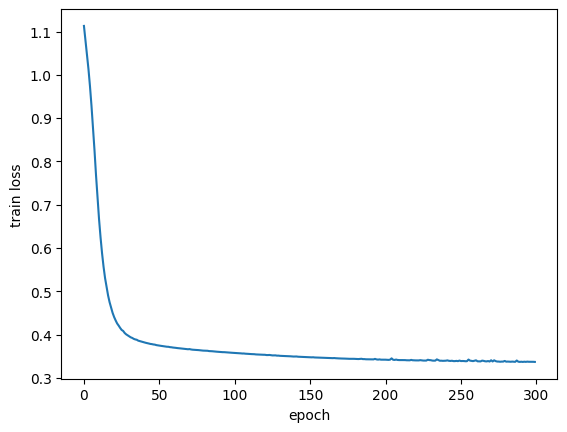

train acc 1.0 test acc 0.9666666666666667


In [ ]:
def accuracy(p, X, y):
    _, c = forward(p, X, onehot(y)); return (c['P'].argmax(1) == y).mean()

def train(seed=0, lr=0.5, epochs=300, bs=64, lam=LAM):
    r = np.random.default_rng(seed); p = init_params(r); hist = []
    Y = onehot(ytr)
    for ep in range(epochs):
        idx = r.permutation(len(ytr)) #this returns the numbers from 0 to 599 in random order
        for s in range(0, len(idx), bs):
            b = idx[s:s+bs]
            loss, cache = forward(p, Xtr[b], Y[b], lam)
            g = backward(cache, p, lam)
            for k in p: p[k] -= lr*g[k]       # gradient descent step
        hist.append(forward(p, Xtr, Y, lam)[0])
    return p, hist

p, hist = train()
plt.plot(hist); plt.xlabel('epoch'); plt.ylabel('train loss'); plt.show()
print("train acc", accuracy(p,Xtr,ytr), "test acc", accuracy(p,Xte,yte))

**D1.** After training, compute the mean of `G` over the training set for each hidden unit. Report units whose mean gate is `< 0.05` or `> 0.95`. What does the gate's local gradient `G(1−G)` imply for such units' ability to learn? Show the numbers.

**D2.** Retrain with `lam=0` and with `lam=0.1`. Compare final `‖W3‖`, train/test accuracy. Explain, using your `backward`, exactly where the regularizer enters the gradient.

**D3.** Replace the row normalization with identity (skip it in forward and backward). Report the gradient norm of `W1` at initialization with and without it. What does normalization do to the gradient scale, and why?

**D4 (open).** Set `EPS_LS=0`. Train, then compare the largest logit magnitude in `S` against the smoothed run. Argue from `∂L/∂S = (P − Ys)/N` why the two behave differently.

**ANSWER (D1–D4):** *(write here, include plots/numbers)*

In [ ]:
#D1

_, c = forward(p, Xtr, onehot(ytr));
means = c['G'].mean(axis=0)
print("means",means)
for j in range(len(means)):
    if means[j] < 0.05 or means[j] > 0.95:
        print("unit", j, "mean gate", means[j], "G(1-G)", means[j] * (1 - means[j]))

#if G<0.05 or G>0.95, G(1-G) is very small and we know dV = delHm*U*G*(1-G) so delV will be smaller, since the gradent of V w.r.t loss is smaller, the unit's abilioty to lern will be smaller

means [0.3701801  0.31330345 0.27058952 0.31996727 0.28542935 0.28663402
 0.29220718 0.3118972  0.28770031 0.24573993]


In [ ]:
#D2


p_0, _ = train(lam=0)
p_01, _ = train(lam=0.1)

w3_norm_0 = np.linalg.norm(p_0['W3'])
w3_norm_01 = np.linalg.norm(p_01['W3'])

print(f"lam=0: ||W3|| = {w3_norm_0:.3f}, "
      f"train acc = {accuracy(p_0, Xtr, ytr):.3f}, "
      f"test acc = {accuracy(p_0, Xte, yte):.3f}")
print(f"lam=0.1: ||W3|| = {w3_norm_01:.3f}, "
      f"train acc = {accuracy(p_01, Xtr, ytr):.3f}, "
      f"test acc = {accuracy(p_01, Xte, yte):.3f}")

#in the backward funciton, we use lambda to find correct dW1, dW2, dW3


lam=0: ||W3|| = 8.532, train acc = 1.000, test acc = 0.950
lam=0.1: ||W3|| = 1.236, train acc = 0.650, test acc = 0.622


In [ ]:
#

## Part E — Conceptual (not code)
**E1.** In `linear_backward`, `dW = Xᵀ·dOut` sums over the batch. Why is the `1/N` factor already inside `dOut` rather than applied here? What would break if both applied it?

**E2.** The gate multiplies two branches. Name the earlier "pattern" it resembles, and say which branch's value scales which branch's gradient.

**E3.** Why does `rownorm_backward` use the **cached** `R` and `n` rather than recomputing from `Hm`? What does this say about the memory/compute trade-off in backprop?

## Grading rubric
| Part | Weight | Full marks require |
|---|---|---|
| A | 25% | Correct derivations, shapes stated at each step |
| B | 40% | All gradchecks < 1e-6, fully vectorized, no autograd |
| C | 15% | Bug identified with a numeric demonstration |
| D | 20% | Numbers shown for each claim; reasoning refers to specific gradient terms |
| E | bonus 5% | Precise, brief answers |

ANS FOR E3:

recomputing from Hm would require us to do the whole stuff again, all the calculation, for all the 600 rows

backprop keeps storing the calculations and moves from the right to left, we don't need to recalculate the right stuff at each local node. so better for memory

couldnt do some questions in between, didn't understand ;-;